<h2 style="border:2px solid #AA5E7A;border-radius:100%; padding:20px; margin:0; color:#AA5E7A; text-align:center">INX Future Inc. – Employee Performance Predictor</h2>


### <center>Feature selection, model training and evaluation </center>
<br>

<h3 style="color:#7F8C6A; border:1px solid #7F8C6A; padding:5px; text-align:center">Loading the Data</h3>

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, json, joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

print(os.getcwd())

C:\Users\alden\Downloads\IABAC_Project\IABAC_Project\src\models


In [3]:
sns.set_theme(style='whitegrid')
RS=42

df = pd.read_csv(r'../../data/processed/employee_clean.csv')
df.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


In [4]:
print(df.shape)


(1200, 28)


In [5]:
# Features and target. EmpNumber is only an ID, so it is dropped.
X=df.drop(columns=['EmpNumber','PerformanceRating'])
y=df.PerformanceRating-2

num_cols=list(X.select_dtypes('number').columns)
cat_cols=[c for c in X.columns if c not in num_cols]
print('Numeric columns    :',len(num_cols))
print('Categorical columns:',cat_cols)

Numeric columns    : 18
Categorical columns: ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime', 'Attrition']


<h3 style="color:#7F8C6A; border:1px solid #7F8C6A; padding:5px; text-align:center">Train Test Split</h3>

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)


In [7]:
print(X_train.shape)
print(X_test.shape)

(960, 26)
(240, 26)


In [8]:
# Baseline: a "model" that always predicts rating 3. Real models must beat this.
baseline_acc = (y_test == 1).mean()
print(f"Baseline accuracy (always predict rating 3): {baseline_acc:.3f}")
print(y_train.value_counts(normalize=True).sort_index().round(3).rename(index={0:'Rating 2',1:'Rating 3',2:'Rating 4'}))

Baseline accuracy (always predict rating 3): 0.729
PerformanceRating
Rating 2    0.161
Rating 3    0.728
Rating 4    0.110
Name: proportion, dtype: float64


In [9]:
X_train.head()

,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,...,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
437,28,Male,Life Sciences,Single,Sales,Sales Executive,Travel_Frequently,7,3,3,...,14,4,5,5,3,4,2,1,3,No
1091,25,Female,Life Sciences,Single,Sales,Sales Executive,Travel_Rarely,4,2,2,...,11,2,5,3,3,5,4,1,3,No
327,25,Female,Medical,Single,Research & Development,Research Scientist,Travel_Rarely,1,3,4,...,18,4,2,3,2,2,2,2,1,No
576,31,Male,Technical Degree,Married,Sales,Sales Executive,Travel_Rarely,5,3,1,...,19,3,6,3,3,5,2,0,2,No
1078,30,Male,Technical Degree,Married,Sales,Sales Representative,Travel_Rarely,2,1,3,...,18,1,1,3,3,1,0,0,0,No


In [10]:
y_train.head()

437     1
1091    0
327     1
576     2
1078    1
Name: PerformanceRating, dtype: int64

<h3 style="color:#7F8C6A; border:1px solid #7F8C6A; padding:5px; text-align:center">Feature Encoding and Standardization</h3>

Numeric columns are standardised (StandardScaler); categorical columns are one-hot encoded (binary columns such as Gender, OverTime and Attrition become one 0/1 column). Below is what the transformed training data looks like. In the models themselves this step sits inside the pipeline.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_pre(num, cat):
    return ColumnTransformer([('num', StandardScaler(), num),
                              ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat)])

pre_demo = make_pre(num_cols, cat_cols)
X_train_scaled = pd.DataFrame(pre_demo.fit_transform(X_train), columns=pre_demo.get_feature_names_out())
print('Encoded feature count:', X_train_scaled.shape[1])
X_train_scaled.head(3)

Encoded feature count: 58


,num__Age,num__DistanceFromHome,num__EmpEducationLevel,num__EmpEnvironmentSatisfaction,num__EmpHourlyRate,num__EmpJobInvolvement,num__EmpJobLevel,num__EmpJobSatisfaction,num__NumCompaniesWorked,num__EmpLastSalaryHikePercent,...,cat__EmpJobRole_Sales Representative,cat__EmpJobRole_Senior Developer,cat__EmpJobRole_Senior Manager R&D,cat__EmpJobRole_Technical Architect,cat__EmpJobRole_Technical Lead,cat__BusinessTravelFrequency_Non-Travel,cat__BusinessTravelFrequency_Travel_Frequently,cat__BusinessTravelFrequency_Travel_Rarely,cat__OverTime_Yes,cat__Attrition_Yes
0,-0.962969,-0.266626,0.121668,0.253129,-0.548057,0.382691,-0.054117,-1.562943,-1.075923,-0.333450,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.287680,-0.631416,-0.820277,-0.660418,1.633634,-1.035778,-0.054117,1.155219,-0.672136,-1.151453,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,-1.287680,-0.996206,0.121668,1.166676,-1.291815,0.382691,-0.949853,-0.656889,-0.672136,0.757221,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


<h2 style="border:2px solid #7F8C6A;border-radius:100%; padding:20px; margin:0; color:#7F8C6A; text-align:center">Model Building</h2>

How every model is evaluated (same steps for all):**
1. **5-fold stratified cross-validation on the training set -> mean and standard deviation of accuracy and macro-F1 (also macro precision and recall).
2. Fit on the full training set, then predict the unseen test set.
3. Print the classification report and confusion matrix.

Macro-averaging gives rating 2 and rating 4 the same weight as rating 3, which matters because rating 3 is about 73% of the data. Models are ranked by cross-validated macro-F1.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, make_scorer)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scoring = {'acc': 'accuracy',
           'f1': 'f1_macro',
           'prec': make_scorer(precision_score, average='macro', zero_division=0),
           'rec': make_scorer(recall_score, average='macro', zero_division=0)}
class_names = ['Rating 2', 'Rating 3', 'Rating 4']

def make_pipeline(model):
    return Pipeline([('pre', make_pre(num_cols, cat_cols)), ('model', model)])

results, fitted = [], {}

def evaluate_model(name, model):
    pipe = make_pipeline(model)
    # 1) cross-validation on the training data (preprocessing is re-fitted inside every fold)
    cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    # 2) fit on the full training set and predict the unseen test set
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(f"{name}: 5-fold CV accuracy = {cvr['test_acc'].mean():.3f} (+/- {cvr['test_acc'].std():.3f}),  "
          f"CV macro-F1 = {cvr['test_f1'].mean():.3f} (+/- {cvr['test_f1'].std():.3f})")
    print()
    print(classification_report(y_test, pred, target_names=class_names, zero_division=0))
    print('Confusion Matrix (rows = actual, columns = predicted):')
    print(pd.DataFrame(confusion_matrix(y_test, pred), index=class_names, columns=class_names))
    results.append({'Model': name,
        'CV accuracy': cvr['test_acc'].mean(), 'CV accuracy std': cvr['test_acc'].std(),
        'CV macro-F1': cvr['test_f1'].mean(), 'CV macro-F1 std': cvr['test_f1'].std(),
        'Test accuracy': accuracy_score(y_test, pred),
        'Test macro-precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Test macro-recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'Test macro-F1': f1_score(y_test, pred, average='macro')})
    fitted[name] = pipe
    return pipe

<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">Baseline (always rating 3)</h3>

In [13]:
from sklearn.dummy import DummyClassifier
base_model = evaluate_model('Baseline (always rating 3)', DummyClassifier(strategy='most_frequent'))

Baseline (always rating 3): 5-fold CV accuracy = 0.728 (+/- 0.002),  CV macro-F1 = 0.281 (+/- 0.000)

              precision    recall  f1-score   support

    Rating 2       0.00      0.00      0.00        39
    Rating 3       0.73      1.00      0.84       175
    Rating 4       0.00      0.00      0.00        26

    accuracy                           0.73       240
   macro avg       0.24      0.33      0.28       240
weighted avg       0.53      0.73      0.61       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2         0        39         0
Rating 3         0       175         0
Rating 4         0        26         0


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">Logistic Regression</h3>

In [14]:
from sklearn.linear_model import LogisticRegression
lr_model = evaluate_model('Logistic Regression', LogisticRegression(class_weight='balanced', max_iter=3000))

Logistic Regression: 5-fold CV accuracy = 0.736 (+/- 0.019),  CV macro-F1 = 0.668 (+/- 0.023)

              precision    recall  f1-score   support

    Rating 2       0.49      0.74      0.59        39
    Rating 3       0.92      0.76      0.83       175
    Rating 4       0.54      0.77      0.63        26

    accuracy                           0.76       240
   macro avg       0.65      0.76      0.69       240
weighted avg       0.81      0.76      0.77       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        29         7         3
Rating 3        28       133        14
Rating 4         2         4        20


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">KNN</h3>

The number of neighbours `k` is **chosen by cross-validation** (inside the training set only), not fixed by hand.

{3: np.float64(0.514), 5: np.float64(0.48), 7: np.float64(0.48), 9: np.float64(0.456), 11: np.float64(0.43), 15: np.float64(0.405), 21: np.float64(0.36)}
Best k by CV macro-F1: 3


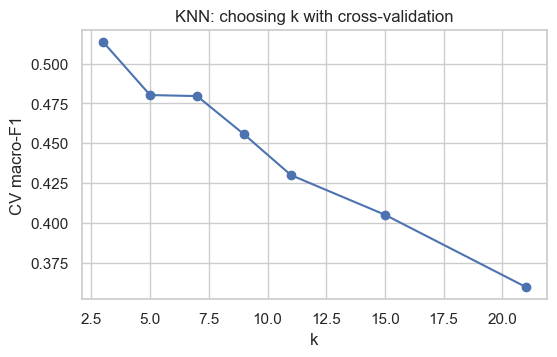

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

k_scores = {k: cross_val_score(make_pipeline(KNeighborsClassifier(n_neighbors=k)), X_train, y_train, cv=cv, scoring='f1_macro').mean()
            for k in [3, 5, 7, 9, 11, 15, 21]}
best_k = max(k_scores, key=k_scores.get)
print({k: round(v, 3) for k, v in k_scores.items()})
print('Best k by CV macro-F1:', best_k)
plt.figure(figsize=(6,3.5)); plt.plot(list(k_scores), list(k_scores.values()), marker='o'); plt.xlabel('k'); plt.ylabel('CV macro-F1'); plt.title('KNN: choosing k with cross-validation'); plt.show()

In [16]:
knn_model = evaluate_model('KNN', KNeighborsClassifier(n_neighbors=best_k))

KNN: 5-fold CV accuracy = 0.739 (+/- 0.026),  CV macro-F1 = 0.514 (+/- 0.057)

              precision    recall  f1-score   support

    Rating 2       0.34      0.28      0.31        39
    Rating 3       0.79      0.89      0.84       175
    Rating 4       0.73      0.31      0.43        26

    accuracy                           0.73       240
   macro avg       0.62      0.49      0.53       240
weighted avg       0.71      0.73      0.71       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        11        28         0
Rating 3        16       156         3
Rating 4         5        13         8


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">SVM</h3>

In [17]:
from sklearn.svm import SVC
svm_model = evaluate_model('SVM (RBF)', SVC(class_weight='balanced', random_state=RS))

SVM (RBF): 5-fold CV accuracy = 0.770 (+/- 0.022),  CV macro-F1 = 0.700 (+/- 0.025)

              precision    recall  f1-score   support

    Rating 2       0.49      0.82      0.62        39
    Rating 3       0.93      0.77      0.84       175
    Rating 4       0.57      0.65      0.61        26

    accuracy                           0.77       240
   macro avg       0.66      0.75      0.69       240
weighted avg       0.82      0.77      0.78       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        32         5         2
Rating 3        29       135        11
Rating 4         4         5        17


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">Decision Tree</h3>

In [18]:
from sklearn.tree import DecisionTreeClassifier
DT_model = evaluate_model('Decision Tree', DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RS))

Decision Tree: 5-fold CV accuracy = 0.887 (+/- 0.019),  CV macro-F1 = 0.837 (+/- 0.023)

              precision    recall  f1-score   support

    Rating 2       0.76      0.90      0.82        39
    Rating 3       0.98      0.91      0.94       175
    Rating 4       0.77      0.92      0.84        26

    accuracy                           0.91       240
   macro avg       0.84      0.91      0.87       240
weighted avg       0.92      0.91      0.91       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        35         3         1
Rating 3        10       159         6
Rating 4         1         1        24


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">Random Forest</h3>

In [19]:
from sklearn.ensemble import RandomForestClassifier
RF_model = evaluate_model('Random Forest', RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RS))

Random Forest: 5-fold CV accuracy = 0.900 (+/- 0.008),  CV macro-F1 = 0.822 (+/- 0.024)

              precision    recall  f1-score   support

    Rating 2       0.91      0.77      0.83        39
    Rating 3       0.91      0.98      0.94       175
    Rating 4       1.00      0.65      0.79        26

    accuracy                           0.91       240
   macro avg       0.94      0.80      0.86       240
weighted avg       0.92      0.91      0.91       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        30         9         0
Rating 3         3       172         0
Rating 4         0         9        17


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">Gradient Boosting</h3>

In [20]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = evaluate_model('Gradient Boosting', GradientBoostingClassifier(random_state=RS))

Gradient Boosting: 5-fold CV accuracy = 0.929 (+/- 0.005),  CV macro-F1 = 0.889 (+/- 0.010)

              precision    recall  f1-score   support

    Rating 2       0.89      0.85      0.87        39
    Rating 3       0.94      0.97      0.96       175
    Rating 4       0.91      0.77      0.83        26

    accuracy                           0.93       240
   macro avg       0.91      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        33         5         1
Rating 3         4       170         1
Rating 4         0         6        20


<h3 style="color:#E5CD82; border:1px solid #E5CD82; padding:5px; text-align:center">Neural Network (MLP)</h3>

In [22]:
from sklearn.neural_network import MLPClassifier
mlp_model = evaluate_model('Neural Network (MLP)', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=800, random_state=RS))

Neural Network (MLP): 5-fold CV accuracy = 0.801 (+/- 0.021),  CV macro-F1 = 0.680 (+/- 0.036)

              precision    recall  f1-score   support

    Rating 2       0.77      0.59      0.67        39
    Rating 3       0.86      0.93      0.89       175
    Rating 4       0.62      0.50      0.55        26

    accuracy                           0.82       240
   macro avg       0.75      0.67      0.70       240
weighted avg       0.82      0.82      0.82       240

Confusion Matrix (rows = actual, columns = predicted):
          Rating 2  Rating 3  Rating 4
Rating 2        23        16         0
Rating 3         5       162         8
Rating 4         2        11        13


<h3 style="color:#7F8C6A; border:1px solid #7F8C6A; padding:5px; text-align:center">Evaluation</h3>

All models side by side: cross-validated scores on the training data (with their spread across the 5 folds) and scores on the unseen test set. Ranked by **CV macro-F1**.

In [23]:
model_results = pd.DataFrame(results).sort_values('CV macro-F1', ascending=False).reset_index(drop=True)
# columns used by other notebooks come first
cols_order = ['Model','CV accuracy','CV macro-F1','Test accuracy','Test macro-F1','CV accuracy std','CV macro-F1 std','Test macro-precision','Test macro-recall']
model_results = model_results[cols_order].round(3)
model_results.to_csv( '../../reports/model_comparison.csv', index=False)
model_results

,Model,CV accuracy,CV macro-F1,Test accuracy,Test macro-F1,CV accuracy std,CV macro-F1 std,Test macro-precision,Test macro-recall
0,Gradient Boosting,0.929,0.889,0.929,0.886,0.005,0.010,0.913,0.862
1,Decision Tree,0.888,0.837,0.908,0.869,0.019,0.023,0.837,0.910
2,Random Forest,0.900,0.822,0.912,0.855,0.008,0.024,0.938,0.802
3,SVM (RBF),0.770,0.700,0.767,0.689,0.022,0.025,0.663,0.749
4,Neural Network (MLP),0.801,0.680,0.825,0.703,0.021,0.036,0.748,0.672
5,Logistic Regression,0.736,0.668,0.758,0.687,0.019,0.023,0.652,0.758
6,KNN,0.739,0.514,0.729,0.527,0.026,0.057,0.621,0.494
7,Baseline (always rating 3),0.728,0.281,0.729,0.281,0.002,0.000,0.243,0.333


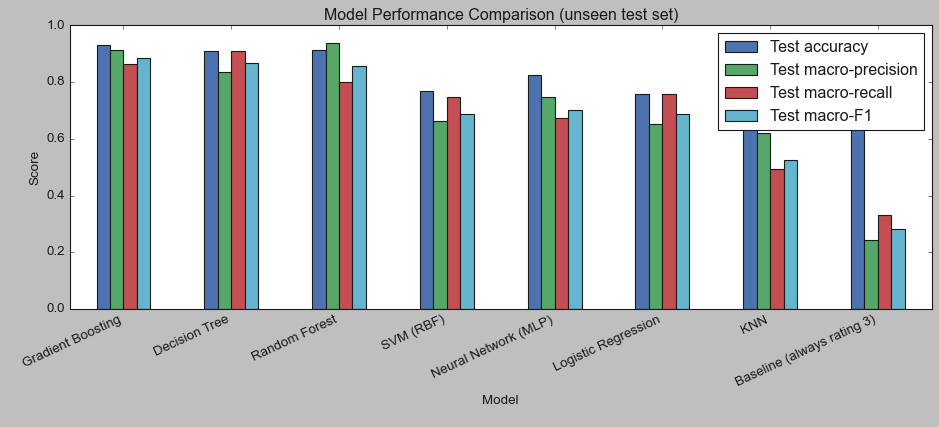

In [24]:
with plt.style.context('classic'):
    model_results.set_index('Model')[['Test accuracy','Test macro-precision','Test macro-recall','Test macro-F1']].plot(kind='bar', figsize=(12,5.5))
    plt.title('Model Performance Comparison (unseen test set)'); 
    plt.ylabel('Score'); 
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha='right');
    plt.tight_layout()

Text(0.5, 1.0, 'Cross-validated macro-F1 for every model')

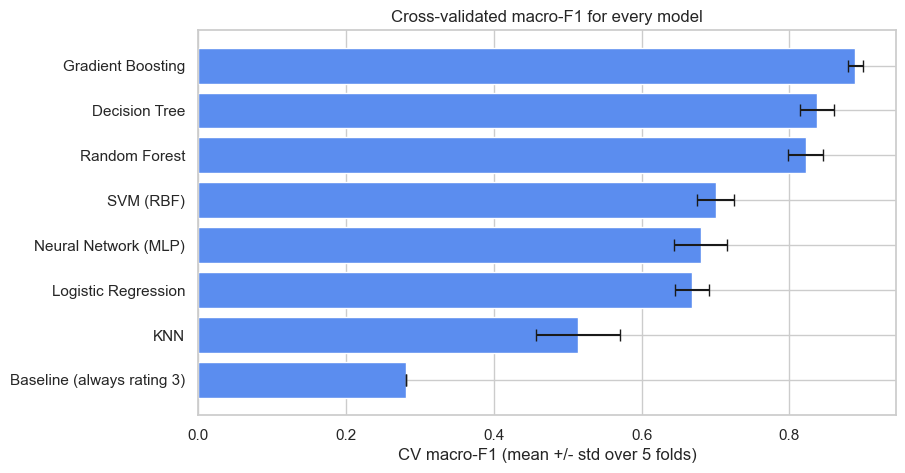

In [25]:
# Cross-validated macro-F1 with its spread across folds
m = model_results.sort_values('CV macro-F1')
plt.figure(figsize=(9,5)); plt.barh(m['Model'], m['CV macro-F1'], xerr=m['CV macro-F1 std'], color='#5b8def', capsize=4)
plt.xlabel('CV macro-F1 (mean +/- std over 5 folds)');
plt.title('Cross-validated macro-F1 for every model')

**Reading:** the tree-based ensembles (Gradient Boosting, Random Forest) and the Decision Tree are clearly ahead of Logistic Regression, SVM, KNN and the neural network, and all beat the baseline. The relationship is non-linear and threshold-like (for example, environment satisfaction 1-2 versus 3-4), which trees capture directly. The small standard deviations show the cross-validated scores are stable across folds.

<h2 style="border:2px solid #7F8C6A;border-radius:100%; padding:20px; margin:0; color:#7F8C6A; text-align:center">Hyperparameter Tuning</h2>

The three strongest families are tuned with a small grid search. **The grid search itself uses 5-fold cross-validation on the training set, scored on macro-F1.** The model with the best cross-validated macro-F1 is selected. **The test set is not used for selection.**

In [26]:
from sklearn.model_selection import GridSearchCV

cands = {'Random Forest': (RandomForestClassifier(class_weight='balanced', random_state=RS),
             {'model__n_estimators':[200,400], 'model__max_depth':[None,12], 'model__min_samples_leaf':[1,3]}),
         'Gradient Boosting': (GradientBoostingClassifier(random_state=RS),
             {'model__n_estimators':[100,200], 'model__learning_rate':[0.05,0.1], 'model__max_depth':[2,3]})}

search = {}
for k, (m_, g) in cands.items():
    gs = GridSearchCV(make_pipeline(m_), g, cv=cv, scoring='f1_macro', n_jobs=2).fit(X_train, y_train)
    search[k] = gs
    print(f'{k:18s} CV macro-F1 = {gs.best_score_:.3f}   best params = {gs.best_params_}')

best_name = max(search, key=lambda k: search[k].best_score_)
final = search[best_name].best_estimator_
print('\nSELECTED MODEL:', best_name)

Random Forest      CV macro-F1 = 0.885   best params = {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}
Gradient Boosting  CV macro-F1 = 0.893   best params = {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100}

SELECTED MODEL: Gradient Boosting


<h2 style="border:2px solid #7F8C6A;border-radius:100%; padding:20px; margin:0; color:#7F8C6A; text-align:center">Final Evaluation of the Selected Model</h2>

In [27]:
pred = final.predict(X_test)
acc = accuracy_score(y_test, pred); mf1 = f1_score(y_test, pred, average='macro')
print('Accuracy:', round(acc,3), '  Macro-F1:', round(mf1,3))
print(classification_report(y_test, pred, target_names=class_names))

Accuracy: 0.929   Macro-F1: 0.891
              precision    recall  f1-score   support

    Rating 2       0.89      0.85      0.87        39
    Rating 3       0.93      0.97      0.95       175
    Rating 4       0.95      0.77      0.85        26

    accuracy                           0.93       240
   macro avg       0.93      0.86      0.89       240
weighted avg       0.93      0.93      0.93       240



Text(0.5, 1.0, 'Confusion matrix – selected model (test set)')

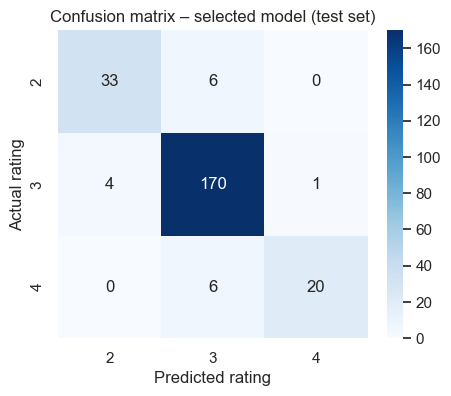

In [28]:
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5,4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[2,3,4], yticklabels=[2,3,4])
plt.xlabel('Predicted rating'); plt.ylabel('Actual rating'); plt.title('Confusion matrix – selected model (test set)')

<h3 style="color:#7F8C6A; border:1px solid #7F8C6A; padding:5px; text-align:center">Cross-validation of the final model</h3>

As a last check, the *tuned* model is cross-validated again, to confirm that the test score is in line with what cross-validation expects.

In [29]:
final_cv = cross_validate(final, X_train, y_train, cv=cv, scoring=scoring)
print(f"Tuned {best_name} – 5-fold CV accuracy: {final_cv['test_acc'].mean():.3f} (+/- {final_cv['test_acc'].std():.3f})   macro-F1: {final_cv['test_f1'].mean():.3f} (+/- {final_cv['test_f1'].std():.3f})")
print(f'Unseen test set        accuracy: {acc:.3f}                      macro-F1: {mf1:.3f}')

Tuned Gradient Boosting – 5-fold CV accuracy: 0.929 (+/- 0.008)   macro-F1: 0.893 (+/- 0.011)
Unseen test set        accuracy: 0.929                      macro-F1: 0.891
